# ขั้นที่ 6: feature เพิ่มเติมที่มีผลต่อการพบซากดึกดำบรรพ์

แนวทางจากงานวิจัย (ค้นเพิ่มตอนเริ่มขั้นนี้):
- **ธรณีวิทยาเป็นตัวกำหนดหลัก** — ระบบ PFYC ของ [BLM](https://www.blm.gov/blog/2021-07-08/pfyc-rapid-assessment-tool-paleontology) จัดศักยภาพซากตามหน่วยหิน;
  แบบจำลองหมวดหิน Cedar Mountain ([Palaeontologia Electronica 2023](https://palaeo-electronica.org/content/2023/3967-cedar-mtn-fm-predictive-model)) ใช้แผนที่ธรณี + ความชัน + Landsat
- **การเปิดเผยของหิน / สิ่งปกคลุมดิน** — โอกาสตรวจพบซากขึ้นกับพื้นที่หินโผล่และสิ่งปกคลุมดินปัจจุบัน
  ([Current Biology 2025](https://discovery.ucl.ac.uk/id/eprint/10206136), [Dunhill et al. 2014](https://www.ncbi.nlm.nih.gov/pmc/articles/PMC4164781/));
  ภาพดาวเทียมช่วงอินฟราเรดสำคัญที่สุดในการหาแหล่งใหม่ ([Gorongosa, PeerJ 2021](https://peerj.com/articles/11573/))
- **การค้นพบ (discovery)** — [Block et al. 2016](https://journals.plos.org/plosone/article?id=10.1371%2Fjournal.pone.0151090) แยกแบบจำลองการค้นพบออกจากการเก็บรักษา;
  งาน SDM เรียก "roadside bias" (การเข้าถึง: ถนน ชุมชน เหมือง — [sampbias](https://www.biorxiv.org/content/10.1101/2020.01.13.903757.full.pdf))

| กลุ่ม | prefix | feature | แหล่งข้อมูล |
|---|---|---|---|
| **ธรณี+** | `gx_` | ระยะถึงรอยเลื่อน / ชั้นหินโค้ง, ระยะถึงรอยสัมผัสหน่วยหิน, จำนวนหน่วยหินใน 2 กม., ชนิดหิน + สภาพแวดล้อมการสะสมตัว | ทธ. เส้นโครงสร้าง 1:250,000; ทธ. หน่วยหิน; [ThaiLex](https://thailex.geolex.org/) |
| **พันเจีย+** | `pgx_` | ระยะถึงแนวชายฝั่งโบราณ ณ แต่ละยุค (บวก = บก, ลบ = ทะเล) ที่ตำแหน่งโบราณ | Scotese PaleoDEM + การหมุนแผ่นเปลือกโลก (notebook 08) |
| **ผิวดิน / น้ำ / การกัดเซาะ** | `lc_` | สัดส่วนสิ่งปกคลุมดินใน 1 กม., น้ำผิวดิน, ระยะถึงแม่น้ำ / ลำธาร, ความหนาแน่นทางน้ำ, ฝน / น้ำท่า / การขาดน้ำ | ESA WorldCover 2021, JRC Global Surface Water, OSM, TerraClimate 2012–2021 |
| **การค้นพบ** *(ทดลองแยก ไม่ใช้ในโมเดลตัวจริง)* | `dc_` | ระยะถึงถนน / ถนนสายหลัก, ความหนาแน่นถนน, ระยะถึงบ่อหิน / พื้นที่ศักยภาพแร่ / อ่างเก็บน้ำ | OSM (Geofabrik), ทธ. พื้นที่ศักยภาพแร่ 1:50,000 |
| **บริบทเชิงพื้นที่** | `sc_` | คำนวณใน notebook 14 แบบ out-of-fold (ใช้ label) | — |

**ไม่ใช้ (เสี่ยงรั่ว)**: ส่วน "Fossils" ของ ThaiLex (ระบุสกุลที่พบในแต่ละหมวดหิน), ขอบเขตแหล่งซากที่ขึ้นทะเบียน / เขตสำรวจซาก / อุทยานธรณี ของ ทธ.
(ถูกกำหนดจากแหล่งซากที่รู้จักอยู่แล้ว)

**ทุก layer เป็นราสเตอร์ทั้งประเทศ 0.002° (~220 ม.)** เก็บใน `data/features/extra_cache/` แล้วดึงค่าที่จุด —
จุด train, กริด 5 กม. และพิกัดใหม่ได้ค่าจากโค้ดเดียวกัน (`feature_lib.extra_features`); รันซ้ำจะข้ามส่วนที่ทำแล้ว

In [1]:
import sys

sys.path.insert(0, ".")
import feature_lib as fl
import model_lib as ml

import glob
import json

import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib import font_manager
from sklearn.metrics import roc_auc_score

_installed = {f.name for f in font_manager.fontManager.ttflist}
THAI_FONT = next((f for f in ["Tahoma", "Thonburi", "Noto Sans Thai", "Leelawadee UI", "Loma", "Garuda"] if f in _installed), None)
plt.rcParams.update({
    "font.family": [THAI_FONT, "DejaVu Sans"] if THAI_FONT else ["DejaVu Sans"], "figure.dpi": 110,
    "axes.spines.top": False, "axes.spines.right": False, "axes.titleweight": "bold", "axes.titlelocation": "left",
})
pd.set_option("display.max_columns", 40, "display.width", 180)
INK, MUTED = "#52514e", "#8a8984"

## 1. สร้าง layer ทั้งประเทศ (ข้ามที่มีแล้ว)

In [2]:
builders = [("โครงสร้างธรณี ทธ. (รอยเลื่อน / ชั้นหินโค้ง)", fl.build_structure), ("รอยสัมผัสหน่วยหิน", fl.build_rock_contacts),
            ("OSM ถนน / ทางน้ำ / บ่อหิน / อ่างเก็บน้ำ", fl.build_osm), ("ทธ. พื้นที่ศักยภาพแร่", fl.build_mineral),
            ("ESA WorldCover", fl.build_worldcover), ("JRC surface water", fl.build_gsw), ("TerraClimate", fl.build_terraclimate)]
for name, b in ml.tqdm_auto()(builders, desc="layer"):
    b()
rows = []
for f in sorted(fl.EXTRA_DIR.glob("*.npz")):
    a = fl.load_raster(f.stem)
    v = a[a > 0] if a.dtype == np.uint8 else a.astype("float32")
    rows.append({"layer": f.stem, "dtype": str(a.dtype), "min": float(np.nanmin(v)) if v.size else 0,
                 "median": float(np.nanmedian(v)) if v.size else 0, "max": float(np.nanmax(v)) if v.size else 0,
                 "MB": round(f.stat().st_size / 1e6, 1)})
pd.DataFrame(rows).set_index("layer").round(2)

OSM: 100%|██████████| 6/6 [00:00<00:00, 2238.75it/s]


,dtype,min,median,max,MB
layer,,,,,
dc_dist_major_road_km,float16,0.0,42.72,461.00,22.7
dc_dist_mineral_km,float16,0.0,44.47,475.25,23.3
dc_dist_quarry_km,float16,0.0,95.81,510.00,25.5
dc_dist_reservoir_km,float16,0.0,49.03,477.50,24.2
dc_dist_road_km,float16,0.0,34.50,460.50,21.8
dc_road_mask,uint8,1.0,1.00,1.00,1.4
gx_dist_contact_km,float16,0.0,39.06,465.25,22.1
gx_dist_fault_km,float16,0.0,83.19,487.00,23.4
gx_dist_fold_km,float16,0.0,137.75,703.50,19.4


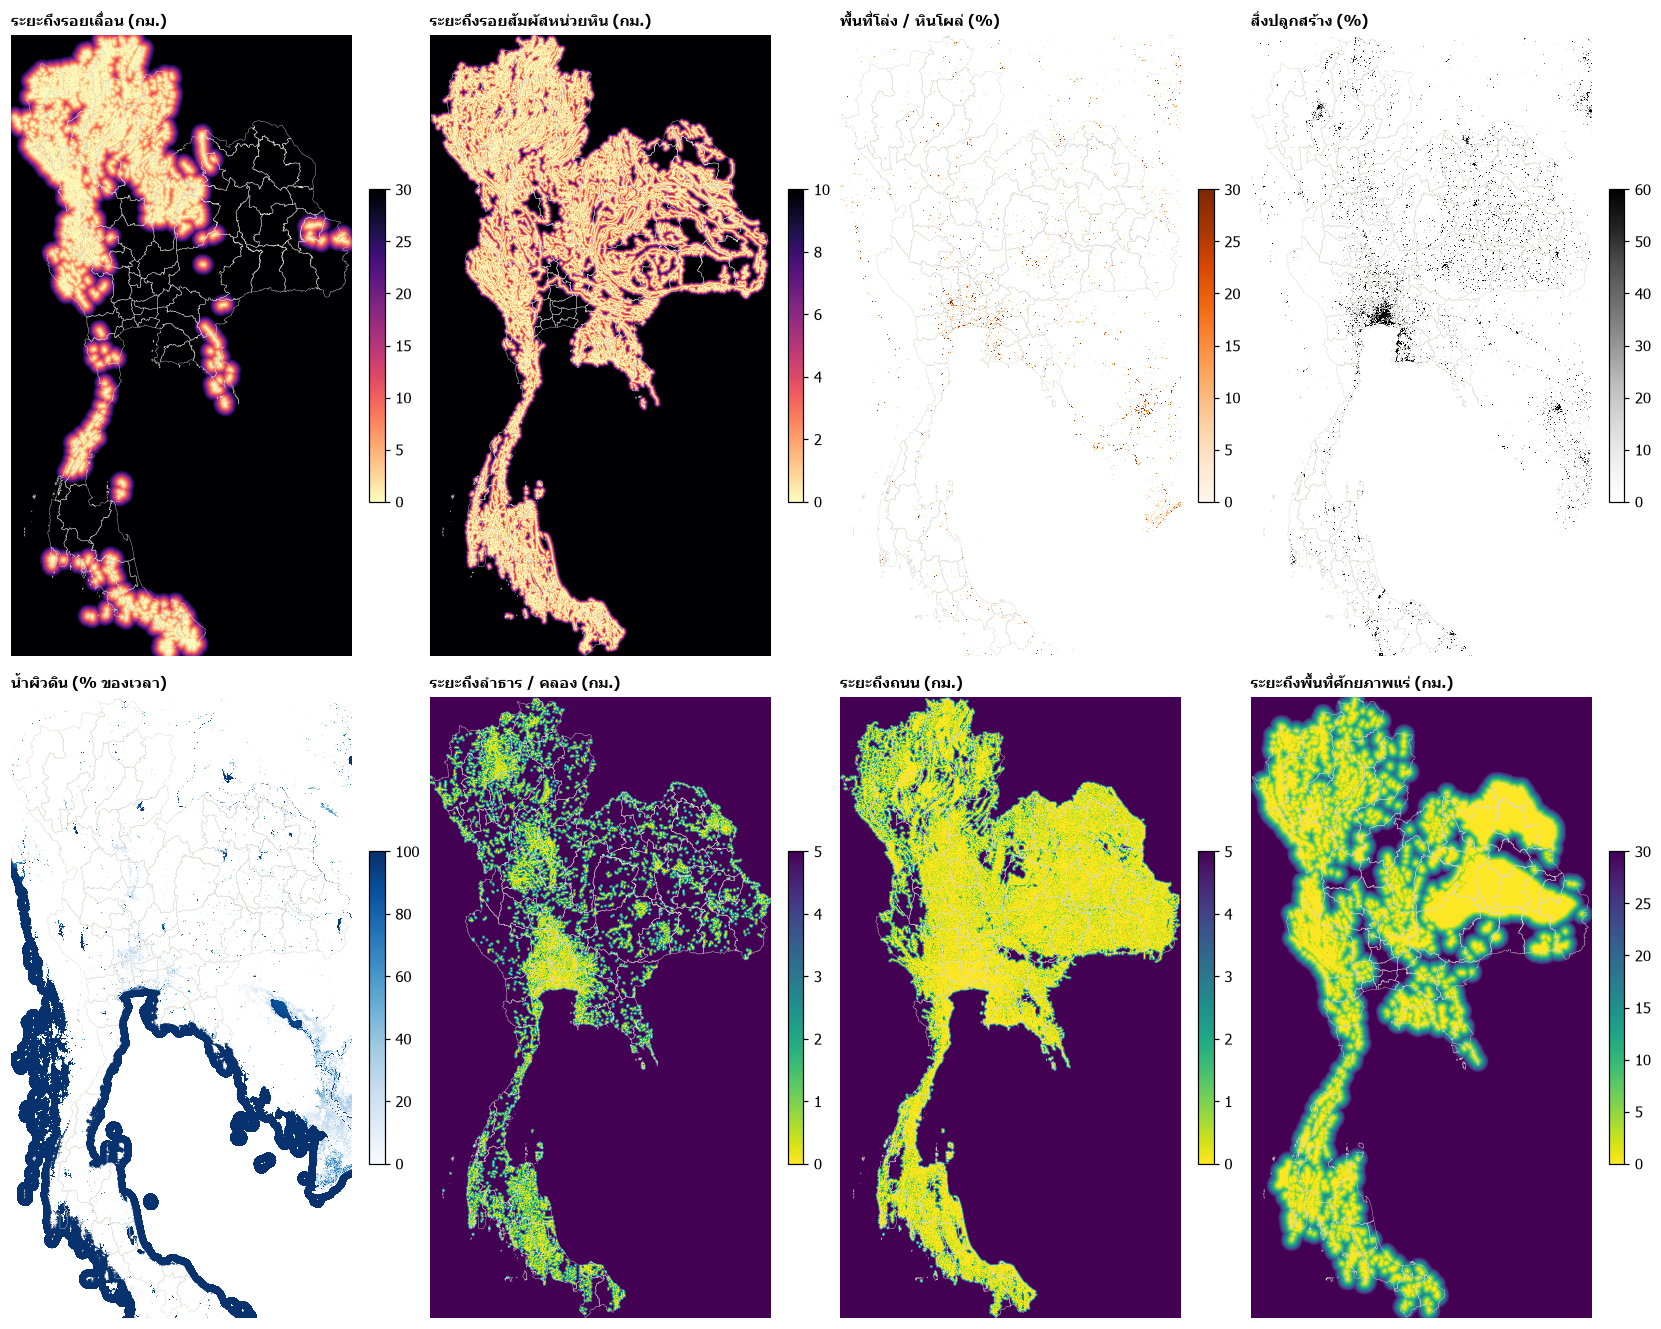

In [3]:
show = [("gx_dist_fault_km", "ระยะถึงรอยเลื่อน (กม.)", "magma_r", 30), ("gx_dist_contact_km", "ระยะถึงรอยสัมผัสหน่วยหิน (กม.)", "magma_r", 10),
        ("lc_wc_bare", "พื้นที่โล่ง / หินโผล่ (%)", "Oranges", 30), ("lc_wc_built", "สิ่งปลูกสร้าง (%)", "Greys", 60),
        ("lc_gsw_occ", "น้ำผิวดิน (% ของเวลา)", "Blues", 100), ("lc_dist_stream_km", "ระยะถึงลำธาร / คลอง (กม.)", "viridis_r", 5),
        ("dc_dist_road_km", "ระยะถึงถนน (กม.)", "viridis_r", 5), ("dc_dist_mineral_km", "ระยะถึงพื้นที่ศักยภาพแร่ (กม.)", "viridis_r", 30)]
prov = gpd.read_file(fl.DATA / "dmr_admin" / "provinces.geojson")
fig, axes = plt.subplots(2, 4, figsize=(15, 12), constrained_layout=True)
for ax, (n, title, cmap, vmax) in zip(axes.ravel(), show):
    a = fl.load_raster(n)[::4, ::4].astype("float32")              # ย่อ 4 เท่าเพื่อแสดงผล
    im = ax.imshow(np.where(a == 0, np.nan, a) if n.startswith("lc_wc") or n == "lc_gsw_occ" else a, cmap=cmap, vmin=0, vmax=vmax,
                   extent=(fl.X_W, fl.X_E, fl.X_S, fl.X_N), interpolation="nearest")
    prov.boundary.plot(ax=ax, color="#d9d8d3", linewidth=0.25)
    ax.set_title(title, fontsize=10)
    ax.set_axis_off()
    fig.colorbar(im, ax=ax, shrink=0.5)

## 2. ชนิดหินจาก ThaiLex

ชื่อหน่วยหินใน legend ของ ทธ. (ภาษาไทย) → หน้า ThaiLex: ตรงชื่อไทยก่อน → ถอดอักษรโรมัน (RTGS) + fuzzy match (≥ 83) →
ตารางจับคู่ด้วยมือ 4 ชื่อที่ตรวจแล้ว; หน่วยที่ไม่มีชื่อ (เช่น `Kgr`, `Tv`) ใช้ตัวอักษรของสัญลักษณ์ (gr = หินแกรนิต, v/bs = หินภูเขาไฟ, Q = ตะกอน)
แล้วจับคำในคำบรรยายหินวิทยา (ไม่ใช้ส่วน Fossils)

In [4]:
lith = fl.rock_unit_lithology()
print("ที่มาของชนิดหิน:", lith.source.str.split(":").str[0].value_counts().to_dict())
flag_cols = [c for c in lith.columns if c.startswith(("lith_", "env_")) or c == "unconsolidated"]
display(lith[lith.source.str.startswith("ThaiLex")].head(12))
lith[flag_cols].sum().rename("หน่วยหิน").to_frame().T

ที่มาของชนิดหิน: {'unknown': 38, 'ThaiLex': 38, 'symbol': 11, 'legend': 7}


,TEXT_SYM,source,unconsolidated,lith_sandstone,lith_fine_clastic,lith_carbonate,lith_conglomerate,lith_chert,lith_evaporite,lith_coal,lith_volcanic,lith_plutonic,lith_metamorphic,env_marine,env_continental
9,Tkb,ThaiLex: Mae Tha Fm,0,1,1,1,1,1,0,0,1,0,0,0,0
12,KTpt,ThaiLex: Phu Thok Fm,0,1,1,0,0,0,1,0,0,0,0,0,0
13,KTms,ThaiLex: Maha Sarakham Fm,0,1,1,0,0,0,1,0,0,0,0,0,0
14,Kkk,ThaiLex: Khok Kruat Fm,0,1,1,0,1,0,0,0,0,0,0,0,0
15,Kpp,ThaiLex: Phu Phan Fm,0,1,1,0,1,0,0,0,0,0,0,0,1
16,Kp,ThaiLex: Phun Phin Fm,0,1,1,0,1,0,0,0,0,0,0,0,0
17,Ksk,ThaiLex: Sao Khua Fm,0,1,1,0,0,0,0,0,0,0,0,0,0
20,JKl,ThaiLex: Lam Thap Fm,0,1,1,0,0,0,0,0,0,0,0,0,0
21,JKpw,ThaiLex: Phra Wihan Fm,0,1,1,0,1,0,0,0,0,0,0,0,0
22,Jk,ThaiLex: Khlong Min Fm,0,1,1,1,0,0,0,0,0,0,0,0,1


,unconsolidated,lith_sandstone,lith_fine_clastic,lith_carbonate,lith_conglomerate,lith_chert,lith_evaporite,lith_coal,lith_volcanic,lith_plutonic,lith_metamorphic,env_marine,env_continental
หน่วยหิน,10,34,34,23,12,7,9,0,13,4,1,4,11


## 3. feature ที่จุด (แหล่ง ทธ., PBDB, background) และกริด 5 กม.

In [5]:
allf = pd.read_parquet(fl.FEAT / "all_features.parquet")
pg = pd.read_parquet(fl.FEAT / "pangea_features.parquet")
cache = fl.FEAT / "extra_features.parquet"
if cache.exists():
    X = pd.read_parquet(cache)
else:
    P = allf[["point_id", "source", "lon", "lat", "geo_rock_sym"]].merge(pg[["point_id"] + [c for c in pg.columns if c.startswith("pg_sw18_l")]], on="point_id")
    parts = []
    for i in ml.tqdm_auto()(range(0, len(P), 2000), desc="จุด train/PBDB"):
        b = P.iloc[i:i + 2000]
        parts.append(fl.extra_features(b, pangea=b, geology=b))
    X = pd.concat([P[["point_id"]], pd.concat(parts)], axis=1)
    X.to_parquet(cache, index=False)
EXTRA_COLS = [c for c in X.columns if c != "point_id"]
groups = {g: [c for c in EXTRA_COLS if c.startswith(p)] for g, p in fl.EXTRA_GROUPS.items()}
print({g: len(v) for g, v in groups.items()}, "| ค่าว่าง:", int(X[EXTRA_COLS].isna().any(axis=1).sum()), "จุด")

{'geo_plus': 30, 'surface': 18, 'discovery': 6} | ค่าว่าง: 137 จุด


In [6]:
gcache = fl.FEAT / "extra_grid.parquet"
grid = pd.read_parquet(fl.FEAT / "grid_5km.parquet")
if gcache.exists():
    XG = pd.read_parquet(gcache)
else:
    G = grid.merge(fl.batch_pangea(grid, tag="grid_"), on="point_id").merge(fl.batch_geology(grid, tag="grid_")[["point_id", "geo_rock_sym"]], on="point_id")
    parts = []
    for i in ml.tqdm_auto()(range(0, len(G), 2000), desc="กริด 5 กม."):
        b = G.iloc[i:i + 2000]
        parts.append(fl.extra_features(b, pangea=b, geology=b))
    XG = pd.concat([G[["point_id"]], pd.concat(parts)], axis=1)
    XG.to_parquet(gcache, index=False)
print("กริด", XG.shape)

กริด (20706, 55)


## 4. ตรวจเบื้องต้น: feature เดี่ยวแยกแหล่ง ทธ. จาก background ได้แค่ไหน (AUC)

AUC 0.5 = แยกไม่ได้; ห่างจาก 0.5 มาก (ทั้งสูงและต่ำ) = มีข้อมูล — เป็นแค่การดูเบื้องต้น ผลจริงต้องดูการทดลองใน notebook 14

,group,bg_bias,bg_uniform,|AUC-0.5| bias
feature,,,,
dc_dist_road_km,discovery,0.309,0.316,0.191
dc_dist_mineral_km,discovery,0.323,0.346,0.177
gx_dist_contact_km,geo_plus,0.357,0.324,0.143
lc_wc_grass_1km,surface,0.624,0.621,0.124
lc_wc_built_1km,surface,0.622,0.608,0.122
gx_units_2km,geo_plus,0.618,0.654,0.118
dc_dist_major_road_km,discovery,0.392,0.395,0.108
dc_road_density_2km,discovery,0.580,0.563,0.080
gx_lith_carbonate,geo_plus,0.574,0.590,0.074


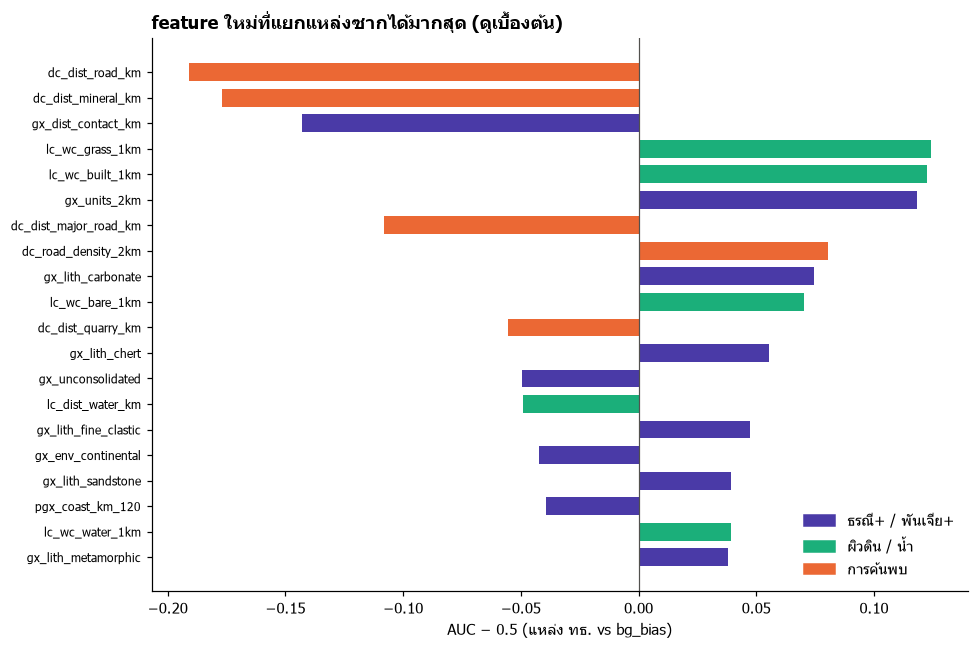

In [7]:
D = allf[["point_id", "source"]].merge(X, on="point_id")
rows = []
for c in EXTRA_COLS:
    r = {"feature": c, "group": next(g for g, p in fl.EXTRA_GROUPS.items() if c.startswith(p))}
    for bg in ["bg_bias", "bg_uniform"]:
        d = D[D.source.isin(["dmr_site", bg])].dropna(subset=[c])
        r[bg] = roc_auc_score(d.source.eq("dmr_site"), d[c]) if d[c].nunique() > 1 else np.nan
    rows.append(r)
uni = pd.DataFrame(rows).set_index("feature")
uni["|AUC-0.5| bias"] = (uni.bg_bias - 0.5).abs()
top = uni.sort_values("|AUC-0.5| bias", ascending=False)
display(top.head(20).style.format({"bg_bias": "{:.3f}", "bg_uniform": "{:.3f}", "|AUC-0.5| bias": "{:.3f}"}))

fig, ax = plt.subplots(figsize=(9, 6))
t = top.head(20)[::-1]
col = {"geo_plus": "#4a3aa7", "surface": "#1baf7a", "discovery": "#eb6834"}
ax.barh(t.index, t.bg_bias - 0.5, color=[col[g] for g in t.group], height=0.7)
ax.axvline(0, color=INK, lw=0.8)
ax.set_xlabel("AUC − 0.5 (แหล่ง ทธ. vs bg_bias)")
ax.set_title("feature ใหม่ที่แยกแหล่งซากได้มากสุด (ดูเบื้องต้น)")
ax.legend([plt.Rectangle((0, 0), 1, 1, color=c) for c in col.values()], ["ธรณี+ / พันเจีย+", "ผิวดิน / น้ำ", "การค้นพบ"], frameon=False, loc="lower right")
ax.tick_params(axis="y", labelsize=8)
plt.tight_layout()

## สรุป

- สร้าง layer ทั้งประเทศ 24 ชั้น (0.002° ≈ 220 ม.) และ feature ใหม่ 54 ตัว: ธรณี+/พันเจีย+ 30, ผิวดิน/น้ำ 18, การค้นพบ 6
  → `data/features/extra_features.parquet` (10,808 จุด) และ `extra_grid.parquet` (กริด 20,706 จุด)
- **ชนิดหิน**: หน่วยหินในแผนที่ ทธ. 94 สัญลักษณ์ ได้ชนิดหินจาก ThaiLex 38, จากตัวอักษรสัญลักษณ์/คำอธิบาย legend 18;
  อีก 38 เป็นหน่วยย่อยหรือหน่วยไม่มีชื่อ (เช่น `Ps-1`, `Pr-2`, `K`, `JK`) ยังไม่มีชนิดหิน — ต่อยอดได้โดยให้หน่วยย่อยใช้ของหน่วยหลัก
- **ดูเบื้องต้น (feature เดี่ยว, แหล่ง ทธ. vs `bg_bias`)**: แยกได้มากสุดคือกลุ่มการค้นพบ — ระยะถึงถนน (AUC 0.31: แหล่งอยู่ใกล้ถนนกว่า)
  และพื้นที่ศักยภาพแร่ (0.32); ตามด้วยระยะถึงรอยสัมผัสหน่วยหิน (0.36: แหล่งอยู่ใกล้รอยต่อหน่วยหิน), สัดส่วนทุ่งหญ้า / สิ่งปลูกสร้าง (0.62),
  จำนวนหน่วยหินใน 2 กม. (0.62) และหินคาร์บอเนต (0.57)
- **ข้อจำกัดของข้อมูล**: แผนที่รอยเลื่อน 1:250,000 แทบไม่มีบนที่ราบสูงโคราช; JRC surface water รวมทะเลชายฝั่ง; ลำธารใน OSM ยังไม่ครบในอีสาน/ภาคเหนือ;
  พื้นที่ศักยภาพแร่คลุมแอ่งเกลือหินในอีสานกว้าง จึงซ้อนกับพื้นที่ไดโนเสาร์ (กลุ่มการค้นพบเป็นการทดลองแยกอยู่แล้ว)
- **แก้ระหว่างทำ**: เซลล์ทะเลของ TerraClimate ให้ผลรวมฝน = 0 ทำให้จุด background ริมฝั่ง 39 จุดได้ "ฝน 0" (สัญญาณปลอม) → ใช้ค่าเซลล์บกใกล้สุด
- ผลจริงของแต่ละกลุ่มดูใน notebook 14 (งานที่ 2) และ 15 (งานที่ 1)